# Controls: % correct against the distance to the nearest fish, four versions

The plots of `EOD_accuracy_plots_2fish.ipynb` / `EOD_accuracy_plots_3fish.ipynb` (10 bins with equal numbers of EODs per panel,
points at the bin median distance, 95% Wilson intervals on the all-EODs panels), for these pipelines:

- **analytic, mask midline**: Denis' analytic model with my mask midline (earlier run, EOD frame);
- **analytic, SLEAP midline**: Denis' analytic model with his SLEAP keypoint midline (his latest run, EOD frame);
- **numerical, shape**: my model (BEM conductivities, sink at the tail tip, × −1), unit-max patterns, L2 (= "numerical, sink at tail tip");
- **numerical, voltage, own g0**: the EOD goes to the fish with the smallest $\lVert r - g_0 L_f^{0.25} m_f\rVert$ (volts), $g_0$ from
  the control itself (median over its better list of the emitter's gain / $L_\mathrm{em}^{0.25}$; in-sample);
- **numerical, voltage, 4-fish g0**: the same with $g_0$ from the 4-fish recordings of the same period (out of sample: median of
  gain / $L_f^{0.25}$ over the clear-emitter EODs of `EOD_gain_vs_length_4fish_<recording>.ipynb`; February for the 2-fish control,
  October for the 3-fish control);
- **numerical, voltage, own g0, best offset**: every fish's model from the masks of video frame Frame + offset (−5 for 2-fish, −4 for
  3-fish, `EOD_accuracy_g0_L025_offset_controls.ipynb`), $g_0$ refitted the same way at that offset;
- **analytic, mask midline, best offset**: Denis' pipeline with my mask midlines taken from the same video frame Frame + offset
  (`EODAssignment/analysis/social_electric_fish_runners/denis_offset_runner_all.py`, all EODs).

Versions (the earlier SLEAP-midline run is used only in the overall-only versions 4 and 5): **1** analytic mask + numerical shape; **2a** + voltage with own g0; **2b** + voltage with 4-fish g0; **3** analytic mask
and voltage (own g0), each at the EOD frame and at the best offset. The distance is the mask-edge distance in the EOD's own frame (`gap_cm`) for
every pipeline. EODs without a pick count as wrong.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

E, PX_PER_CM, N = 0.25, 912 / 60, 150
OUT = 'results/baseline_g0/vs_distance'; os.makedirs(OUT, exist_ok=True)
REC = {
    '2-fish (2024-02-13)': dict(res='results/eod_ground_truth', letters={'A': 1, 'B': 0}, cache='conductivities/model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
                                lengths='fish_lengths_2fish.json', fish=(0, 1), emitter=1, offset=-5, n_better=3501,
                                period=['2024-02-20T21_16_26', '2024-02-20T18_16_24'], xlabel='distance from fish 1 to fish 0 (cm, mask edge to edge)'),
    '3-fish (2024-10-15)': dict(res='results/eod_ground_truth_3fish', letters={'A': 1, 'B': 2, 'C': 0}, cache='conductivities/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
                                lengths='fish_lengths_3fish.json', fish=(0, 1, 2), emitter=0, offset=-4, n_better=6751,
                                period=['2024-10-23T15_18_28'], xlabel='distance from fish 0 to the nearest other fish (cm, mask edge to edge)'),
}
SHAPE = 'fish | BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip'
STYLE = {   # colour follows the pipeline in every version
    'analytic, SLEAP midline': ('#1F5FBF', 'D'),
    'analytic, mask midline': ('#17A0B0', 'D'),
    'numerical, shape': ('#C8361E', 'o'),
    'numerical, voltage, own g0': ('#F08A24', 's'),
    'numerical, voltage, 4-fish g0': ('#C9A227', '^'),
    'numerical, voltage, own g0, best offset': ('#6B1A0C', 'v'),
    'analytic, mask midline, best offset': ('#0B4F8A', 'p'),
}
VERSIONS = {
    'v1_analytic_mask_vs_shape': ['analytic, mask midline', 'numerical, shape'],
    'v2a_plus_voltage_own_g0': ['analytic, mask midline', 'numerical, shape', 'numerical, voltage, own g0'],
    'v2b_plus_voltage_4fish_g0': ['analytic, mask midline', 'numerical, shape', 'numerical, voltage, 4-fish g0'],
    'v3_voltage_best_offset': ['analytic, mask midline', 'analytic, mask midline, best offset', 'numerical, voltage, own g0',
                               'numerical, voltage, own g0, best offset'],
}
OVERALL_ONLY = {   # no offset; bars left to right
    'v4_no_offset_sleap_mask_numerical': ['analytic, SLEAP midline', 'analytic, mask midline', 'numerical, shape'],
    'v5_no_offset_sleap_numerical': ['analytic, SLEAP midline', 'numerical, shape'],
}

def wilson(k, n, z=1.96):
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)

def period_g0(recs):
    s = []
    for rec in recs:
        t = pd.read_csv(f'results/eod_gain_4fish/{rec}/selected_eods.csv'); j = json.load(open(f'results/eod_gain_4fish/{rec}/fish_lengths_4fish.json'))
        L = np.array([j['fish'][str(f)]['L_px'] / j['px_per_cm'] for f in range(4)])
        s.append(t.gain_ls / L[t.fish] ** E)
    return float(np.median(pd.concat(s)))

def assign(R, M, scale):
    dist = np.linalg.norm(R[:, None] - scale[None, :, None] * M, axis=2)
    dist = np.where(np.isfinite(dist), dist, np.inf)
    return np.where(np.isfinite(dist.min(1)), dist.argmin(1), -1)

def own_g0(R, M, em, better, L):
    ok = better & np.isfinite(M[:, em]).all(1)
    return float(np.median((R[ok] * M[ok, em]).sum(1) / (M[ok, em] ** 2).sum(1)) / L[em] ** E)

G0_OFF0 = pd.read_csv('results/baseline_g0/g0_controls.csv').set_index(['recording', 'EODs']).xs('all better-list EODs', level='EODs')['g0 = median g / L^e']

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'grid.linewidth': 0.8, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b', 'xtick.color': '#5a5a55',
                     'ytick.color': '#5a5a55'})

## Picks of every pipeline

In [2]:
D, G = {}, {}
for name, c in REC.items():
    A = pd.read_csv(f"{c['res']}/conductivities/eod_assignments.csv", index_col='row')
    cache = pd.read_pickle(f"{c['res']}/{c['cache']}")
    assert (cache.frame.to_numpy() == A.Frame.to_numpy()).all()
    if c['emitter'] == 1:   # 2-fish: Denis' mask-midline run, as EOD_accuracy_plots_2fish.ipynb
        S = pd.read_csv('results/eod_assignment_2_fish_silent/eod_assignment_summary.csv')
        assert (S.Frame.to_numpy() == A.Frame.to_numpy()).all()
        mask = S.discharging_fish_mask_midline.map({'A': 1, 'B': 0}).to_numpy()
    else:
        mask = A["fish | Denis' pipeline with my mask midline"].to_numpy()
    better = A.Frame.isin(pd.read_csv(f"{c['res']}/good_frames_better_list.csv").frame).to_numpy()
    assert better.sum() == c['n_better']
    j = json.load(open(f"{c['res']}/{c['lengths']}"))
    L = np.array([j['fish'][str(f)]['L_px'] for f in c['fish']]) / PX_PER_CM
    R = np.stack(cache.v_rec.map(np.asarray))
    M0 = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))
    U = pd.read_pickle(f"{c['res']}/conductivities/model_voltages_N{N}_sink0_bem_offset{c['offset']}.pkl")
    Mb = -np.stack([U[int(k)] for k in A.Frame])
    em = c['emitter']
    g = {'own g0': G0_OFF0.loc[name], '4-fish g0': period_g0(c['period']), 'own g0, best offset': own_g0(R, Mb, em, better, L)}   # own g0 at offset 0: EOD_baseline_g0.ipynb
    G[name] = {**g, 'best offset': c['offset']}
    picks = pd.DataFrame({
        'analytic, SLEAP midline': A["fish | Denis' pipeline (latest run)"].to_numpy(),
        'analytic, mask midline': mask,
        'numerical, shape': A[SHAPE].to_numpy(),
        'numerical, voltage, own g0': assign(R, M0, g['own g0'] * L ** E),
        'numerical, voltage, 4-fish g0': assign(R, M0, g['4-fish g0'] * L ** E),
        'numerical, voltage, own g0, best offset': assign(R, Mb, g['own g0, best offset'] * L ** E),
    }, index=A.index)
    dn = pd.read_csv(f"{c['res']}/conductivities/denis_mask_midline_offset/denis_mask_midline_all_eods_offset{c['offset']}.csv")
    assert (dn.eod_row.to_numpy() == A.index.to_numpy()).all()
    picks['analytic, mask midline, best offset'] = dn.pick.map(c['letters']).to_numpy()   # NaN: no mask midline (wrong)
    picks.insert(0, 'Frame', A.Frame); picks.insert(1, 'gap_cm', A.gap_cm); picks.insert(2, 'better list', better)
    picks.to_csv(f"{OUT}/picks_{name.split(' ')[0]}.csv")
    D[name] = dict(P=picks, em=em, sets={'all EODs': np.ones(len(A), bool), 'better list of good frames': better})
display(pd.DataFrame(G).T)

,own g0,4-fish g0,"own g0, best offset",best offset
2-fish (2024-02-13),0.247369,0.198933,0.252377,-5.0
3-fish (2024-10-15),0.493815,0.456811,0.522190,-4.0


## Overall % correct (all pipelines)

In [3]:
rows = []
for name, d in D.items():
    for s, m in d['sets'].items():
        for p in STYLE:
            k, n = int((d['P'].loc[m, p] == d['em']).sum()), int(m.sum()); lo, hi = wilson(k, n)
            rows.append({'recording': name, 'EODs': s, 'pipeline': p, '% correct': 100 * k / n, '95% CI low': lo, '95% CI high': hi, 'n EODs': n})
OVERALL = pd.DataFrame(rows); OVERALL.to_csv(f'{OUT}/accuracy_overall_versions.csv', index=False)
display(OVERALL.pivot_table(index='pipeline', columns=['recording', 'EODs'], values='% correct', sort=False).round(2))

recording                               2-fish (2024-02-13)  \
EODs                                               all EODs   
pipeline                                                      
analytic, SLEAP midline                               89.75   
analytic, mask midline                                93.09   
numerical, shape                                      93.65   
numerical, voltage, own g0                            92.50   
numerical, voltage, 4-fish g0                         93.34   
numerical, voltage, own g0, best offset               96.97   
analytic, mask midline, best offset                   96.74   

recording                                                           \
EODs                                    better list of good frames   
pipeline                                                             
analytic, SLEAP midline                                      95.94   
analytic, mask midline                                       96.97   
numerical, shape                                             96.74   
numerical, voltage, own g0                                   97.14   
numerical, voltage, 4-fish g0                                97.57   
numerical, voltage, own g0, best offset                      99.34   
analytic, mask midline, best offset                          99.11   

recording                               3-fish (2024-10-15)  \
EODs                                               all EODs   
pipeline                                                      
analytic, SLEAP midline                               82.44   
analytic, mask midline                                86.99   
numerical, shape                                      86.55   
numerical, voltage, own g0                            89.08   
numerical, voltage, 4-fish g0                         88.83   
numerical, voltage, own g0, best offset               91.35   
analytic, mask midline, best offset                   90.61   

recording                                                           
EODs                                    better list of good frames  
pipeline                                                            
analytic, SLEAP midline                                      94.07  
analytic, mask midline                                       95.20  
numerical, shape                                             94.50  
numerical, voltage, own g0                                   97.56  
numerical, voltage, 4-fish g0                                97.39  
numerical, voltage, own g0, best offset                      98.84  
analytic, mask midline, best offset                          98.87

## Accuracy against distance and overall, per version

In [4]:
def plot_distance(version, pipes):
    fig, axs = plt.subplots(2, 2, figsize=(16, 11))
    tabs = []
    for row, (name, d) in zip(axs, D.items()):
        for a, (s, m) in zip(row, d['sets'].items()):
            sub = d['P'][m & d['P'].gap_cm.notna().to_numpy()]
            gr = sub.groupby(pd.qcut(sub.gap_cm, 10, duplicates='drop'), observed=True); x = gr.gap_cm.median().to_numpy(); n = gr.size().to_numpy()
            for j, p in enumerate(pipes):
                c, mk = STYLE[p]
                k = gr[p].apply(lambda v: (v == d['em']).sum()).to_numpy(); pct = 100 * k / n; lo, hi = wilson(k, n)
                err = None if s == 'better list of good frames' else [pct - lo, hi - pct]
                a.errorbar(x * (1 + 0.012 * (j - (len(pipes) - 1) / 2)), pct, yerr=err, color=c, marker=mk, ms=8, ls='-', lw=2, capsize=3, mfc=c, mew=1.5,
                           mec='white', label=p)
                tabs.append(pd.DataFrame({'recording': name, 'EODs': s, 'pipeline': p, 'median distance (cm)': x, 'n EODs': n, '% correct': pct,
                                          '95% CI low': lo, '95% CI high': hi}))
            a.set(title=f'{name}, {s}: {len(sub):,} EODs with a distance', xlabel=REC[name]['xlabel'])
            a.set_ylabel(f"% EODs assigned to fish {d['em']} (correct)")
    h, l = axs[0, 0].get_legend_handles_labels()
    fig.legend(h, l, ncol=len(pipes), loc='lower center', frameon=False, fontsize=11)
    plt.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(f'{OUT}/accuracy_vs_distance_{version}.png', dpi=120); plt.show()
    t = pd.concat(tabs); t.to_csv(f'{OUT}/accuracy_vs_distance_{version}.csv', index=False)
    return t

def plot_overall(version, pipes):
    fig, axs = plt.subplots(1, 2, figsize=(15, 5.6))
    w = 0.8 / len(pipes)
    for a, name in zip(axs, D):
        t = OVERALL[OVERALL.recording == name].set_index(['EODs', 'pipeline'])
        sets = list(D[name]['sets'])
        for j, p in enumerate(pipes):
            v = np.array([t.loc[(s, p), '% correct'] for s in sets])
            lo = v - np.array([t.loc[(s, p), '95% CI low'] for s in sets]); hi = np.array([t.loc[(s, p), '95% CI high'] for s in sets]) - v
            xs = np.arange(len(sets)) + (j - (len(pipes) - 1) / 2) * w
            a.bar(xs, v, w * 0.95, color=STYLE[p][0], edgecolor='white', lw=1, label=p)
            a.errorbar(xs, v, yerr=[lo, hi], fmt='none', ecolor='#2b2b2b', capsize=3, lw=1)
            for xx, vv, hh in zip(xs, v, hi): a.text(xx, vv + hh + 0.2, f'{vv:.1f}', ha='center', va='bottom', fontsize=9.5, color='#2b2b2b')
        a.set_xticks(np.arange(len(sets)))
        a.set_xticklabels([f"{s}\n(n = {int(D[name]['sets'][s].sum()):,} EODs)" for s in sets])
        a.set(ylim=(80, 101), title=name, ylabel=f"% EODs assigned to fish {D[name]['em']} (correct)")
        a.set_axisbelow(True); a.grid(axis='x', visible=False)
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, ncol=len(pipes), loc='lower center', frameon=False, fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(f'{OUT}/accuracy_overall_{version}.png', dpi=120); plt.show()

### Version 1: analytic (mask midline) vs numerical shape

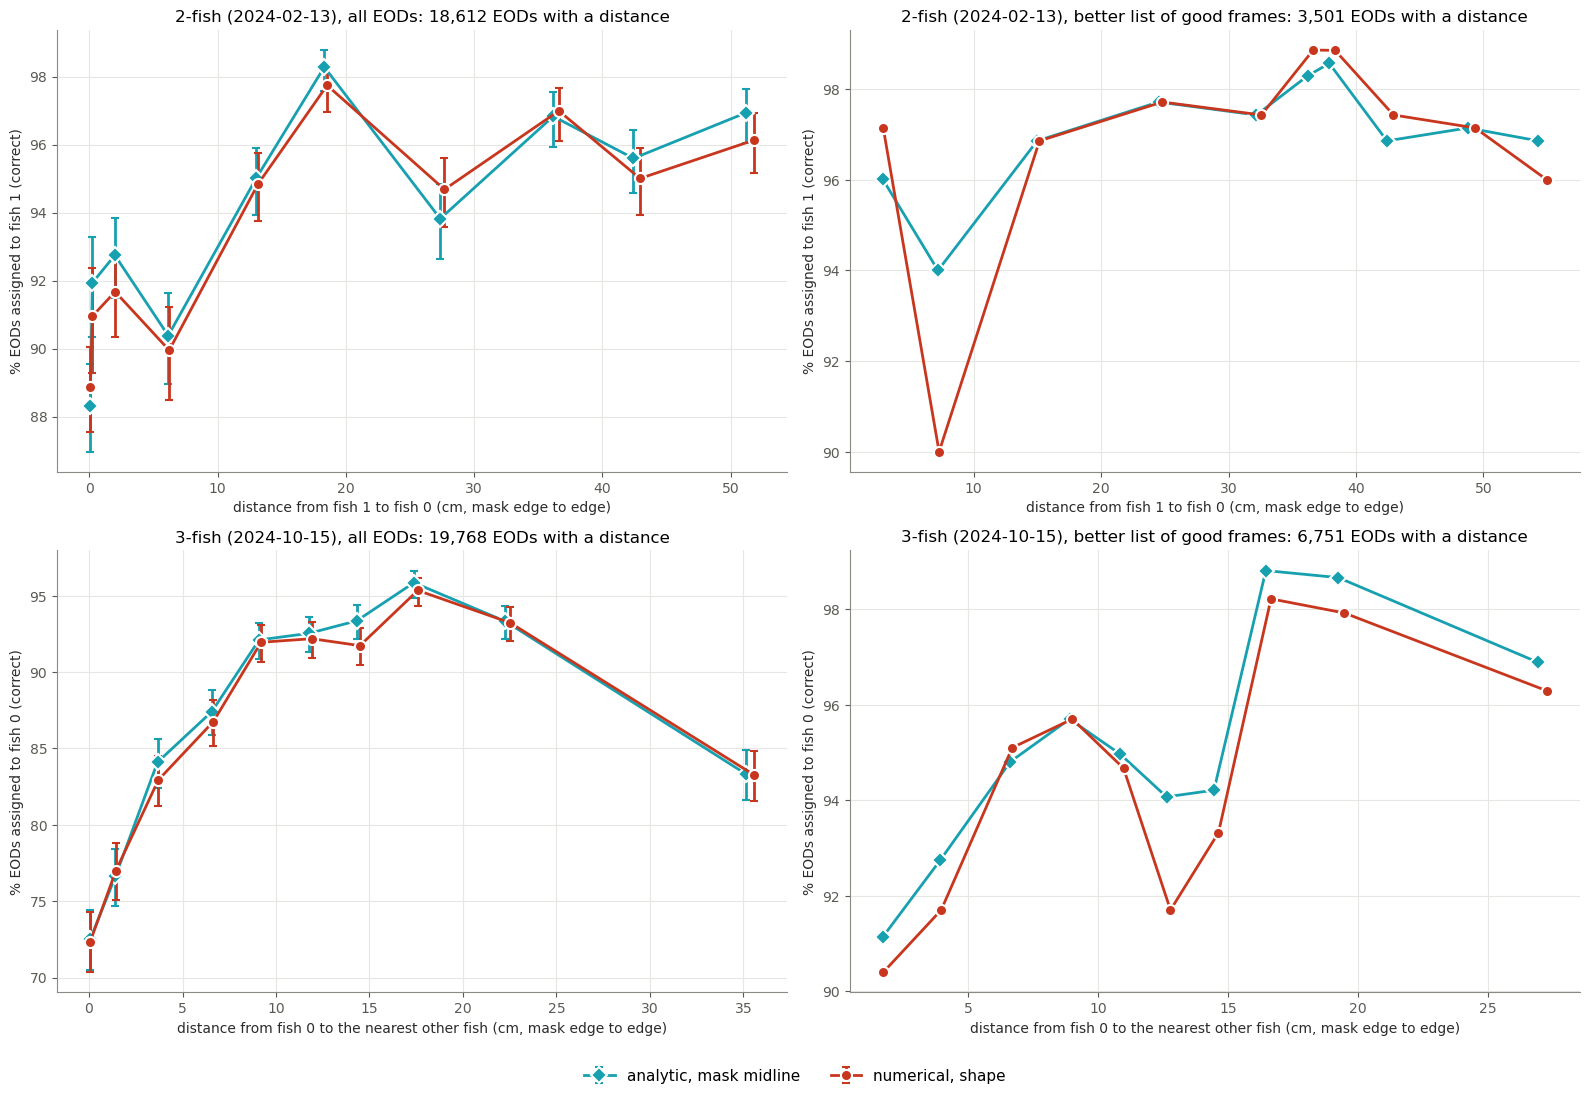

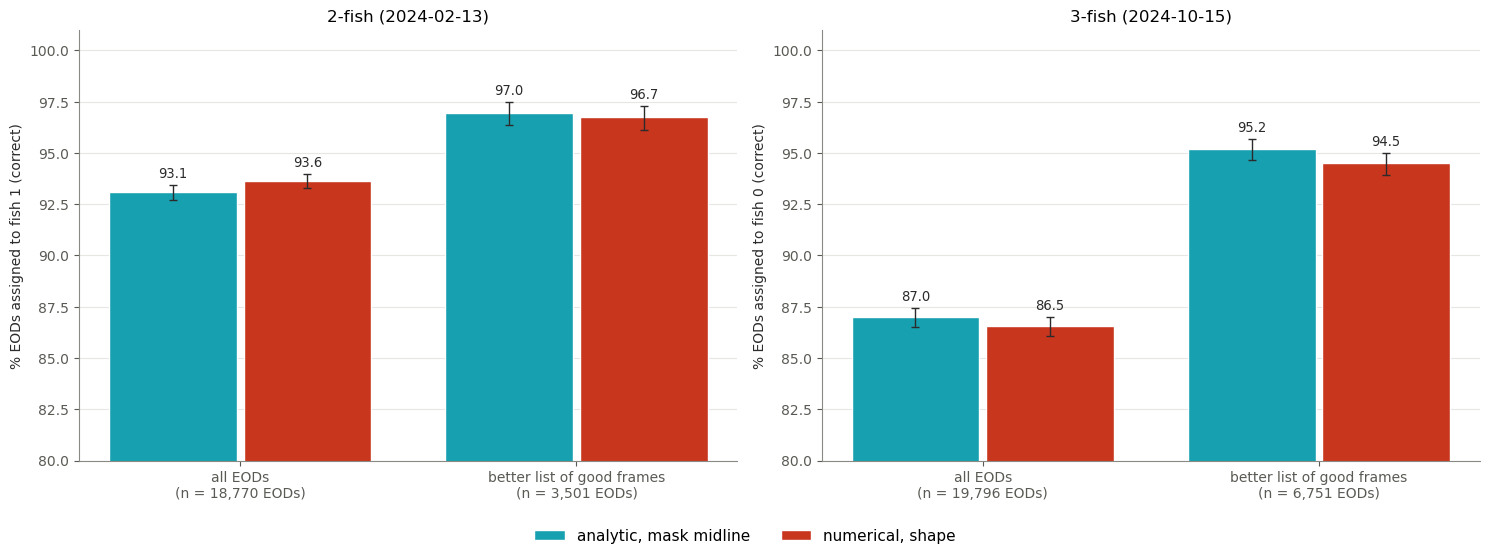

pipeline                                                             analytic, mask midline  \
recording           EODs                       median distance (cm)                           
2-fish (2024-02-13) all EODs                   0.065789                                88.3   
                                               0.237207                                91.9   
                                               1.997661                                92.7   
                                               6.185610                                90.4   
                                               13.080198                               95.0   
                                               18.425751                               98.3   
                                               27.522734                               93.8   
                                               36.385386                               96.8   
                                               42.681095                               95.6   
                                               51.536594                               96.9   
                    better list of good frames 2.873728                                96.0   
                                               7.236842                                94.0   
                                               15.066723                               96.9   
                                               24.647705                               97.7   
                                               32.380787                               97.4   
                                               36.416539                               98.3   
                                               38.127937                               98.6   
                                               42.684999                               96.9   
                                               49.057093                               97.1   
                                               54.643870                               96.9   
3-fish (2024-10-15) all EODs                   0.065789                                72.5   
                                               1.423244                                76.6   
                                               3.686559                                84.1   
                                               6.607340                                87.4   
                                               9.148286                                92.1   
                                               11.842105                               92.5   
                                               14.403238                               93.4   
                                               17.478964                               95.9   
                                               22.393368                               93.3   
                                               35.366172                               83.3   
                    better list of good frames 1.706727                                91.1   
                                               3.926480                                92.7   
                                               6.646202                                94.8   
                                               8.948336                                95.7   
                                               10.909553                               95.0   
                                               12.708272                               94.1   
                                               14.546021                               94.2   
                                               16.557657                               98.8   
                                               19.368493                               98.7   
                                               27.121307                               96.9   

pipeline 

In [5]:
t = plot_distance('v1_analytic_mask_vs_shape', VERSIONS['v1_analytic_mask_vs_shape'])
plot_overall('v1_analytic_mask_vs_shape', VERSIONS['v1_analytic_mask_vs_shape'])
display(t.pivot_table(index=['recording', 'EODs', 'median distance (cm)'], columns='pipeline', values='% correct', sort=False).round(1))

### Version 2a: + numerical voltage, g0 from the control itself

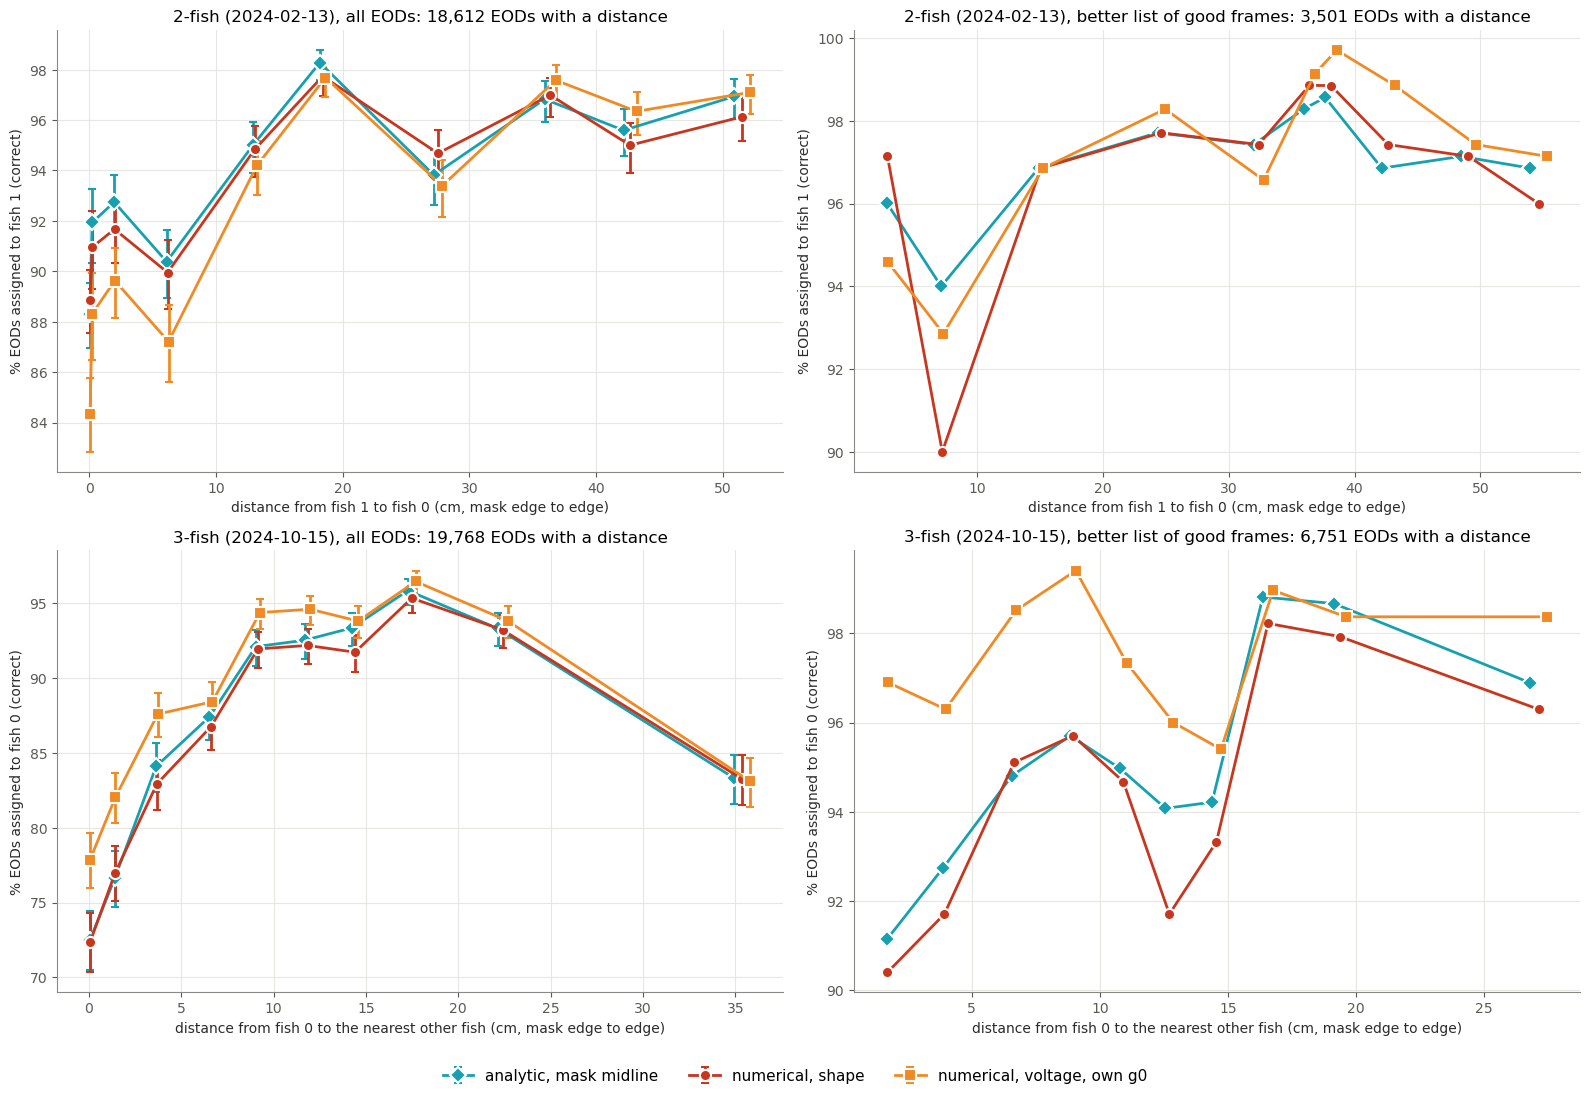

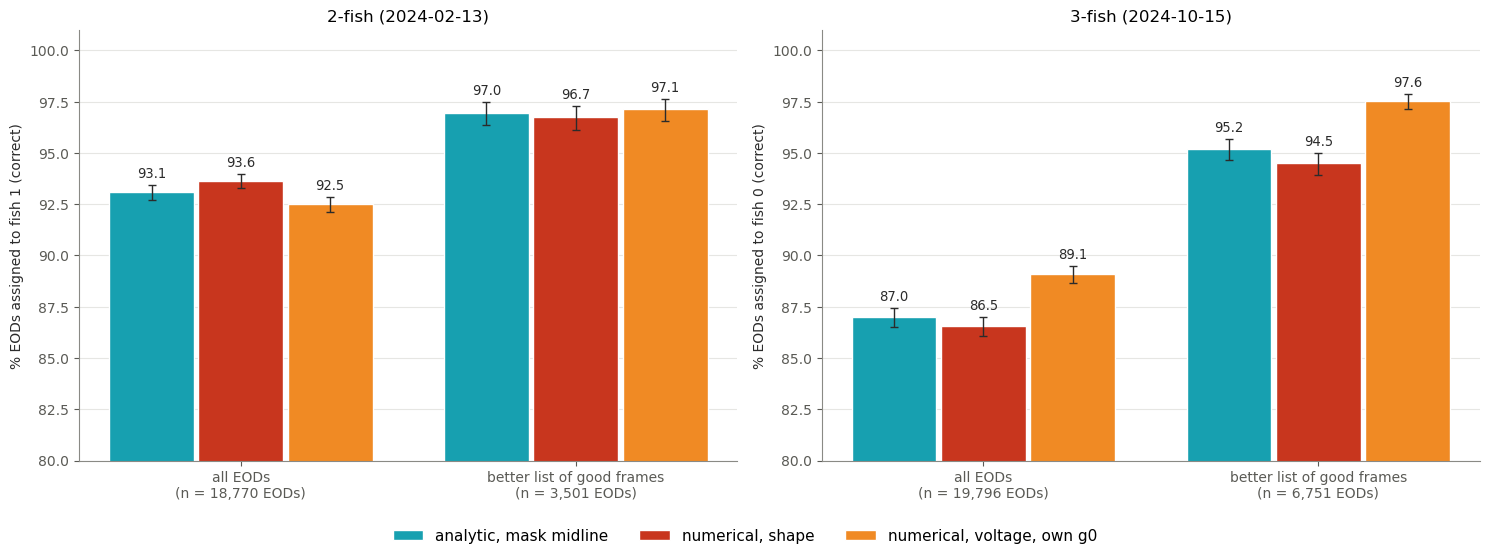

pipeline                                                             analytic, mask midline  \
recording           EODs                       median distance (cm)                           
2-fish (2024-02-13) all EODs                   0.065789                                88.3   
                                               0.237207                                91.9   
                                               1.997661                                92.7   
                                               6.185610                                90.4   
                                               13.080198                               95.0   
                                               18.425751                               98.3   
                                               27.522734                               93.8   
                                               36.385386                               96.8   
                                               42.681095                               95.6   
                                               51.536594                               96.9   
                    better list of good frames 2.873728                                96.0   
                                               7.236842                                94.0   
                                               15.066723                               96.9   
                                               24.647705                               97.7   
                                               32.380787                               97.4   
                                               36.416539                               98.3   
                                               38.127937                               98.6   
                                               42.684999                               96.9   
                                               49.057093                               97.1   
                                               54.643870                               96.9   
3-fish (2024-10-15) all EODs                   0.065789                                72.5   
                                               1.423244                                76.6   
                                               3.686559                                84.1   
                                               6.607340                                87.4   
                                               9.148286                                92.1   
                                               11.842105                               92.5   
                                               14.403238                               93.4   
                                               17.478964                               95.9   
                                               22.393368                               93.3   
                                               35.366172                               83.3   
                    better list of good frames 1.706727                                91.1   
                                               3.926480                                92.7   
                                               6.646202                                94.8   
                                               8.948336                                95.7   
                                               10.909553                               95.0   
                                               12.708272                               94.1   
                                               14.546021                               94.2   
                                               16.557657                               98.8   
                                               19.368493                               98.7   
                                               27.121307                               96.9   

pipeline 

In [6]:
t = plot_distance('v2a_plus_voltage_own_g0', VERSIONS['v2a_plus_voltage_own_g0'])
plot_overall('v2a_plus_voltage_own_g0', VERSIONS['v2a_plus_voltage_own_g0'])
display(t.pivot_table(index=['recording', 'EODs', 'median distance (cm)'], columns='pipeline', values='% correct', sort=False).round(1))

### Version 2b: + numerical voltage, g0 from the same-period 4-fish recordings

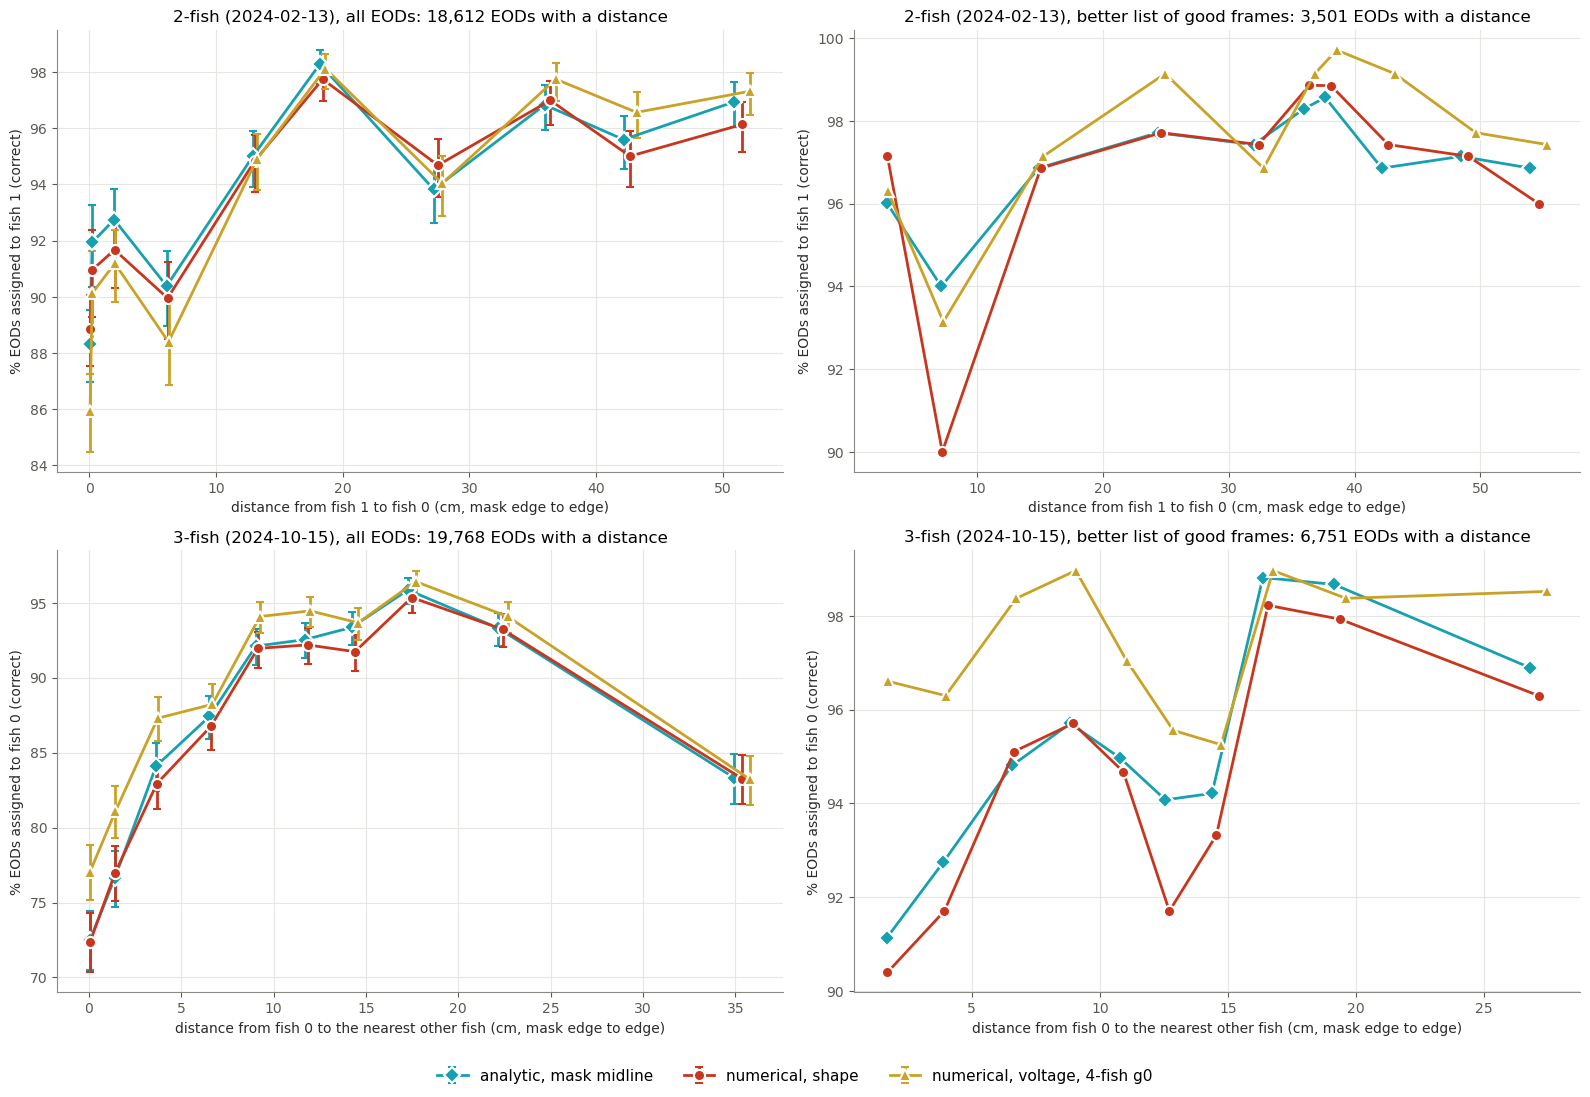

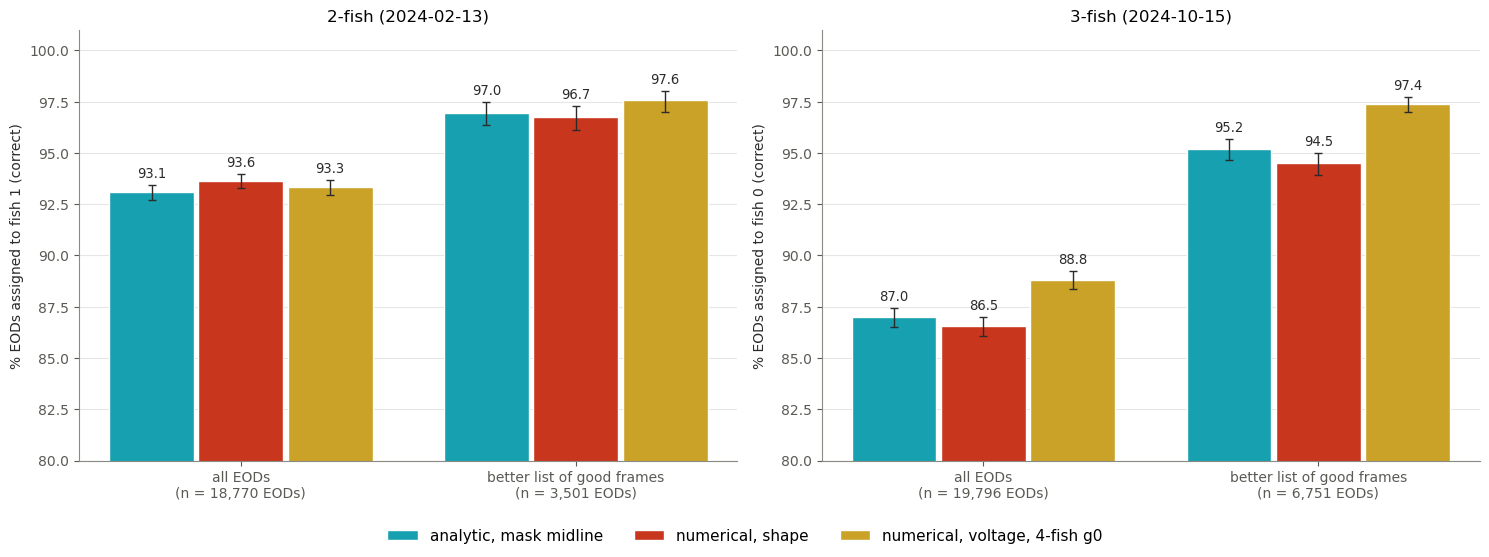

pipeline                                                             analytic, mask midline  \
recording           EODs                       median distance (cm)                           
2-fish (2024-02-13) all EODs                   0.065789                                88.3   
                                               0.237207                                91.9   
                                               1.997661                                92.7   
                                               6.185610                                90.4   
                                               13.080198                               95.0   
                                               18.425751                               98.3   
                                               27.522734                               93.8   
                                               36.385386                               96.8   
                                               42.681095                               95.6   
                                               51.536594                               96.9   
                    better list of good frames 2.873728                                96.0   
                                               7.236842                                94.0   
                                               15.066723                               96.9   
                                               24.647705                               97.7   
                                               32.380787                               97.4   
                                               36.416539                               98.3   
                                               38.127937                               98.6   
                                               42.684999                               96.9   
                                               49.057093                               97.1   
                                               54.643870                               96.9   
3-fish (2024-10-15) all EODs                   0.065789                                72.5   
                                               1.423244                                76.6   
                                               3.686559                                84.1   
                                               6.607340                                87.4   
                                               9.148286                                92.1   
                                               11.842105                               92.5   
                                               14.403238                               93.4   
                                               17.478964                               95.9   
                                               22.393368                               93.3   
                                               35.366172                               83.3   
                    better list of good frames 1.706727                                91.1   
                                               3.926480                                92.7   
                                               6.646202                                94.8   
                                               8.948336                                95.7   
                                               10.909553                               95.0   
                                               12.708272                               94.1   
                                               14.546021                               94.2   
                                               16.557657                               98.8   
                                               19.368493                               98.7   
                                               27.121307                               96.9   

pipeline 

In [7]:
t = plot_distance('v2b_plus_voltage_4fish_g0', VERSIONS['v2b_plus_voltage_4fish_g0'])
plot_overall('v2b_plus_voltage_4fish_g0', VERSIONS['v2b_plus_voltage_4fish_g0'])
display(t.pivot_table(index=['recording', 'EODs', 'median distance (cm)'], columns='pipeline', values='% correct', sort=False).round(1))

### Version 3: analytic (mask midline) and numerical voltage, each at the EOD frame and at the best offset

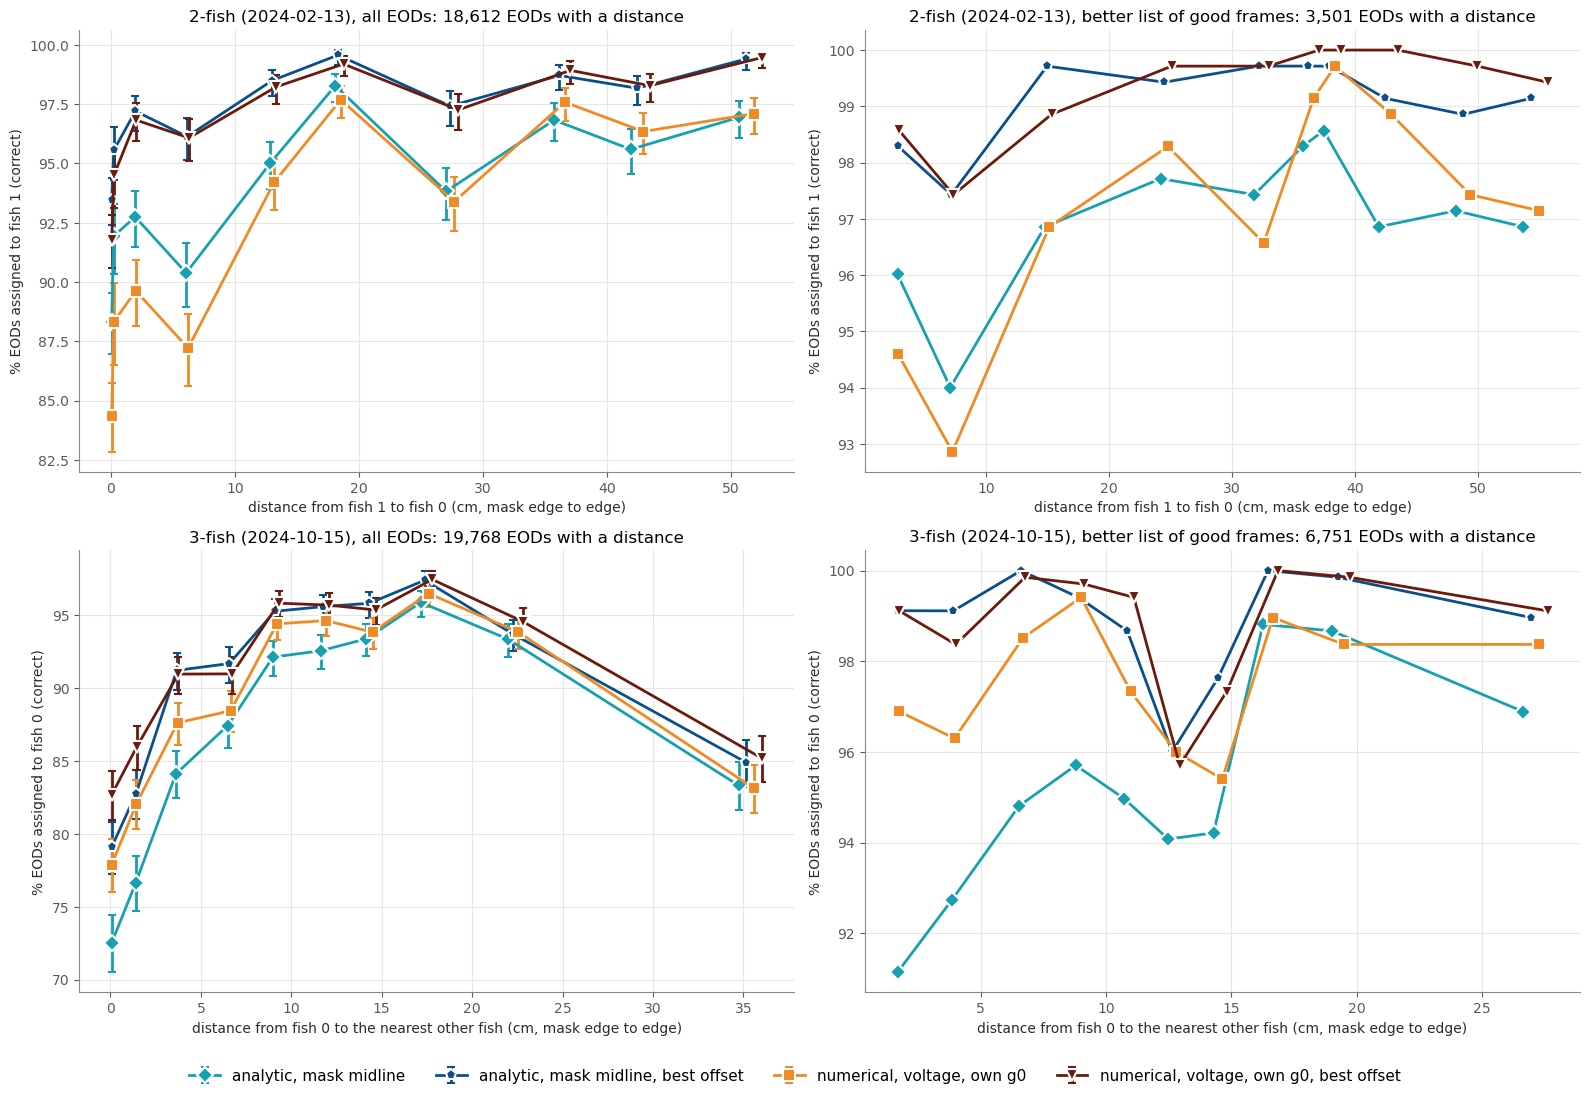

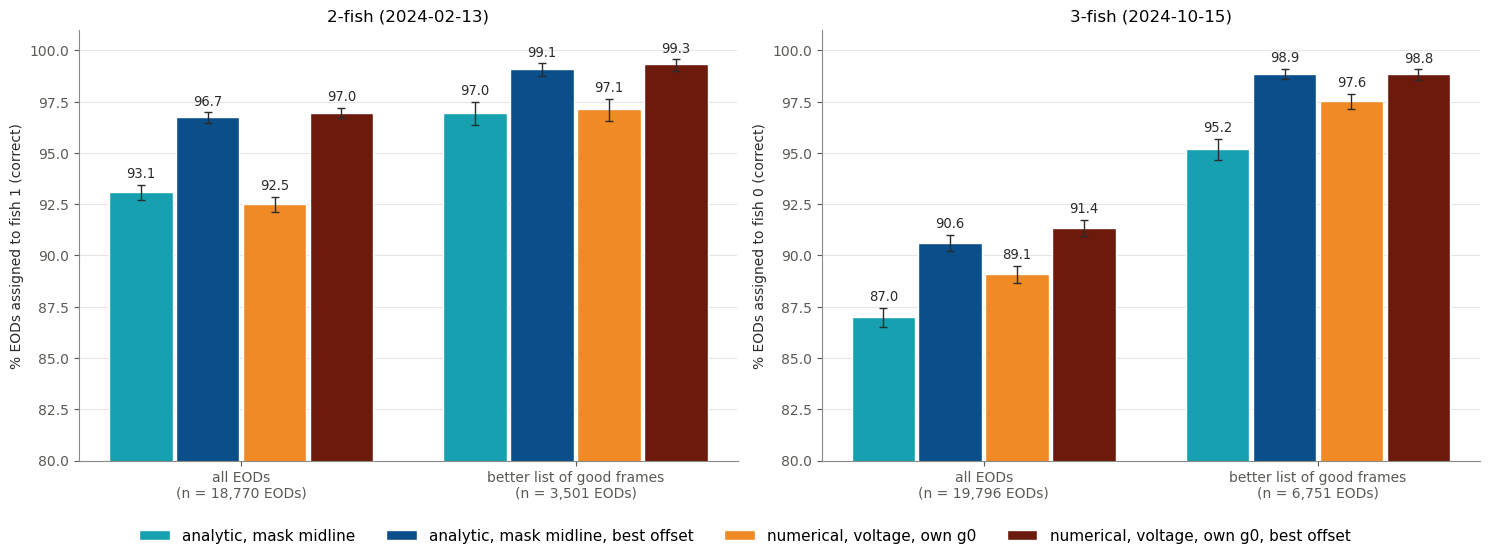

pipeline                                                             analytic, mask midline  \
recording           EODs                       median distance (cm)                           
2-fish (2024-02-13) all EODs                   0.065789                                88.3   
                                               0.237207                                91.9   
                                               1.997661                                92.7   
                                               6.185610                                90.4   
                                               13.080198                               95.0   
                                               18.425751                               98.3   
                                               27.522734                               93.8   
                                               36.385386                               96.8   
                                               42.681095                               95.6   
                                               51.536594                               96.9   
                    better list of good frames 2.873728                                96.0   
                                               7.236842                                94.0   
                                               15.066723                               96.9   
                                               24.647705                               97.7   
                                               32.380787                               97.4   
                                               36.416539                               98.3   
                                               38.127937                               98.6   
                                               42.684999                               96.9   
                                               49.057093                               97.1   
                                               54.643870                               96.9   
3-fish (2024-10-15) all EODs                   0.065789                                72.5   
                                               1.423244                                76.6   
                                               3.686559                                84.1   
                                               6.607340                                87.4   
                                               9.148286                                92.1   
                                               11.842105                               92.5   
                                               14.403238                               93.4   
                                               17.478964                               95.9   
                                               22.393368                               93.3   
                                               35.366172                               83.3   
                    better list of good frames 1.706727                                91.1   
                                               3.926480                                92.7   
                                               6.646202                                94.8   
                                               8.948336                                95.7   
                                               10.909553                               95.0   
                                               12.708272                               94.1   
                                               14.546021                               94.2   
                                               16.557657                               98.8   
                                               19.368493                               98.7   
                                               27.121307                               96.9   

pipeline 

In [8]:
t = plot_distance('v3_voltage_best_offset', VERSIONS['v3_voltage_best_offset'])
plot_overall('v3_voltage_best_offset', VERSIONS['v3_voltage_best_offset'])
display(t.pivot_table(index=['recording', 'EODs', 'median distance (cm)'], columns='pipeline', values='% correct', sort=False).round(1))

### Versions 4 and 5: overall % correct without any offset
**4** analytic (SLEAP midline), analytic (mask midline), numerical shape; **5** analytic (SLEAP midline), numerical shape (bars left
to right).

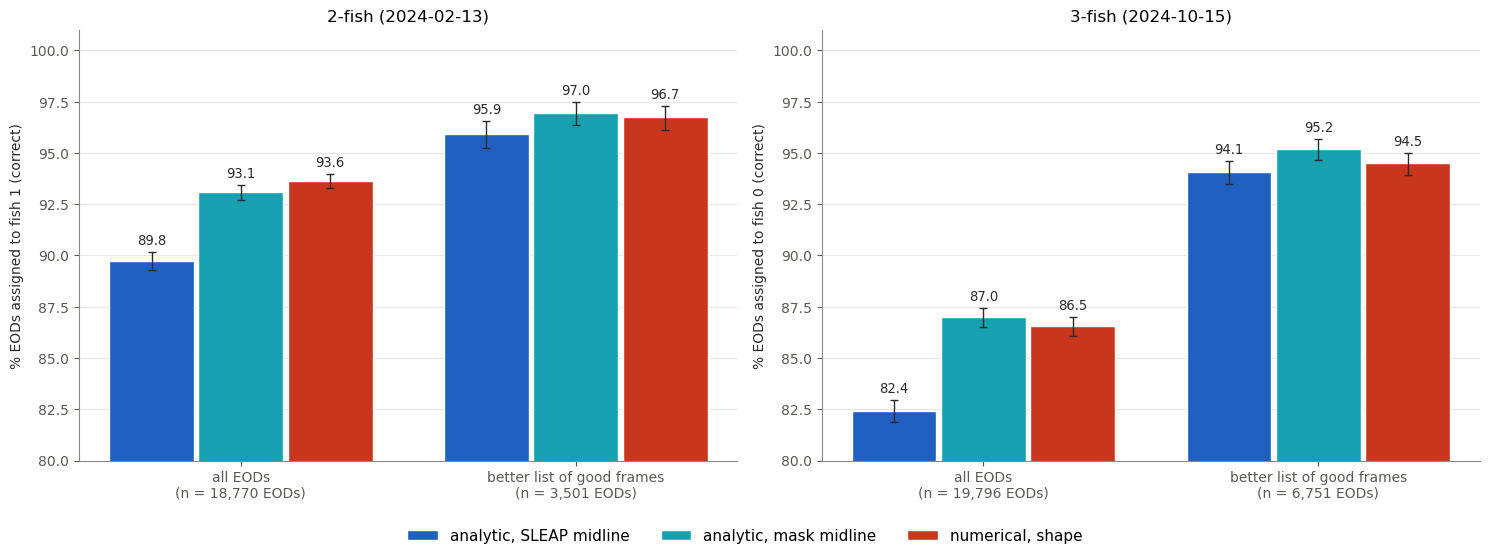

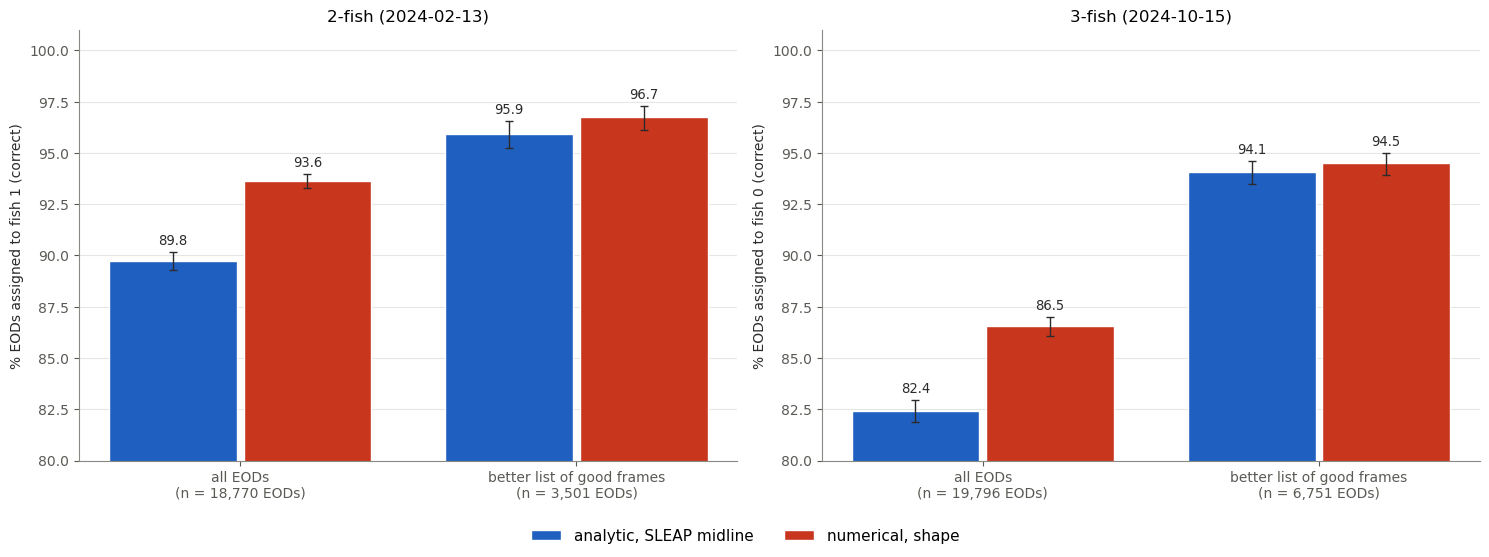

recording               2-fish (2024-02-13)                             \
EODs                               all EODs better list of good frames   
pipeline                                                                 
analytic, SLEAP midline               89.75                      95.94   
analytic, mask midline                93.09                      96.97   
numerical, shape                      93.65                      96.74   

recording               3-fish (2024-10-15)                             
EODs                               all EODs better list of good frames  
pipeline                                                                
analytic, SLEAP midline               82.44                      94.07  
analytic, mask midline                86.99                      95.20  
numerical, shape                      86.55                      94.50

In [9]:
for v, pipes in OVERALL_ONLY.items():
    plot_overall(v, pipes)
display(OVERALL[OVERALL.pipeline.isin(OVERALL_ONLY['v4_no_offset_sleap_mask_numerical'])]
        .pivot_table(index='pipeline', columns=['recording', 'EODs'], values='% correct', sort=False).round(2))